# Visualização — Gráficos 300 DPI
**Responsável:** F5 · **Aprovador:** F1  
Projeto Final de Big Data — DataRoute Recife (UNINASSAU, 6º noturno)

> Regra: use apenas os caminhos de `src/config.py`. Nada de `C:/...` ou `/content/drive/...`.

In [1]:
# Setup padrão (NÃO ALTERAR): funciona local e no Google Colab
import sys
from pathlib import Path
try:
    import google.colab  # noqa: F401
    if not Path('dataroute-recife').exists() and not Path('src').exists():
        !git clone -q https://github.com/pcsdv0/dataroute-recife.git
    if Path('dataroute-recife').exists():
        %cd dataroute-recife
    !pip install -q -r requirements.txt
except ImportError:
    pass
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import *          # caminhos relativos oficiais
from src.utils import ler_csv_robusto, salvar_csv
if not SILVER_SINISTROS.exists():  # gera Bronze -> Silver -> Gold se ainda não existir
    from src.pipeline import executar
    executar()

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from src.config import *          # GOLD_ARQUIVOS, FIGURAS_DIR, DPI_FIGURAS

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"savefig.dpi": DPI_FIGURAS, "axes.titleweight": "bold"})
AZUL, VERMELHO = "#2a6f97", "#c1121f"
from matplotlib.ticker import FuncFormatter

def br(v, casas=0):
    """Número no padrão brasileiro: 14.254 e 46,0."""
    s = f"{v:,.{casas}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

FMT_BR = FuncFormatter(lambda v, _: br(v))

# Nomes de bairro com acento para exibição (a Silver guarda sem acento)
ACENTOS_BAIRRO = {"Sao Jose": "São José", "Agua Fria": "Água Fria", "Graças": "Graças",
                  "Gracas": "Graças", "Varzea": "Várzea", "Torreao": "Torreão",
                  "Torroes": "Torrões", "Jiquia": "Jiquiá", "Jordao": "Jordão",
                  "Santo Antonio": "Santo Antônio", "Caxanga": "Caxangá",
                  "Hipodromo": "Hipódromo", "Tejipio": "Tejipió", "Toto": "Totó"}

def carregar(chave, nome_arquivo):
    """Usa GOLD_ARQUIVOS[chave]; se a chave não existir, procura na mesma pasta gold."""
    if chave in GOLD_ARQUIVOS:
        return pd.read_csv(GOLD_ARQUIVOS[chave])
    pasta = Path(next(iter(GOLD_ARQUIVOS.values()))).parent
    return pd.read_csv(pasta / nome_arquivo)

def salvar_fig(fig, nome, nota=None):
    if nota:
        fig.text(0.01, -0.01, nota, fontsize=8, style="italic", ha="left", va="top", wrap=True)
    caminho = FIGURAS_DIR / nome
    fig.savefig(caminho, dpi=DPI_FIGURAS, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Salvo: {caminho.relative_to(ROOT).as_posix()} ({DPI_FIGURAS} dpi)")

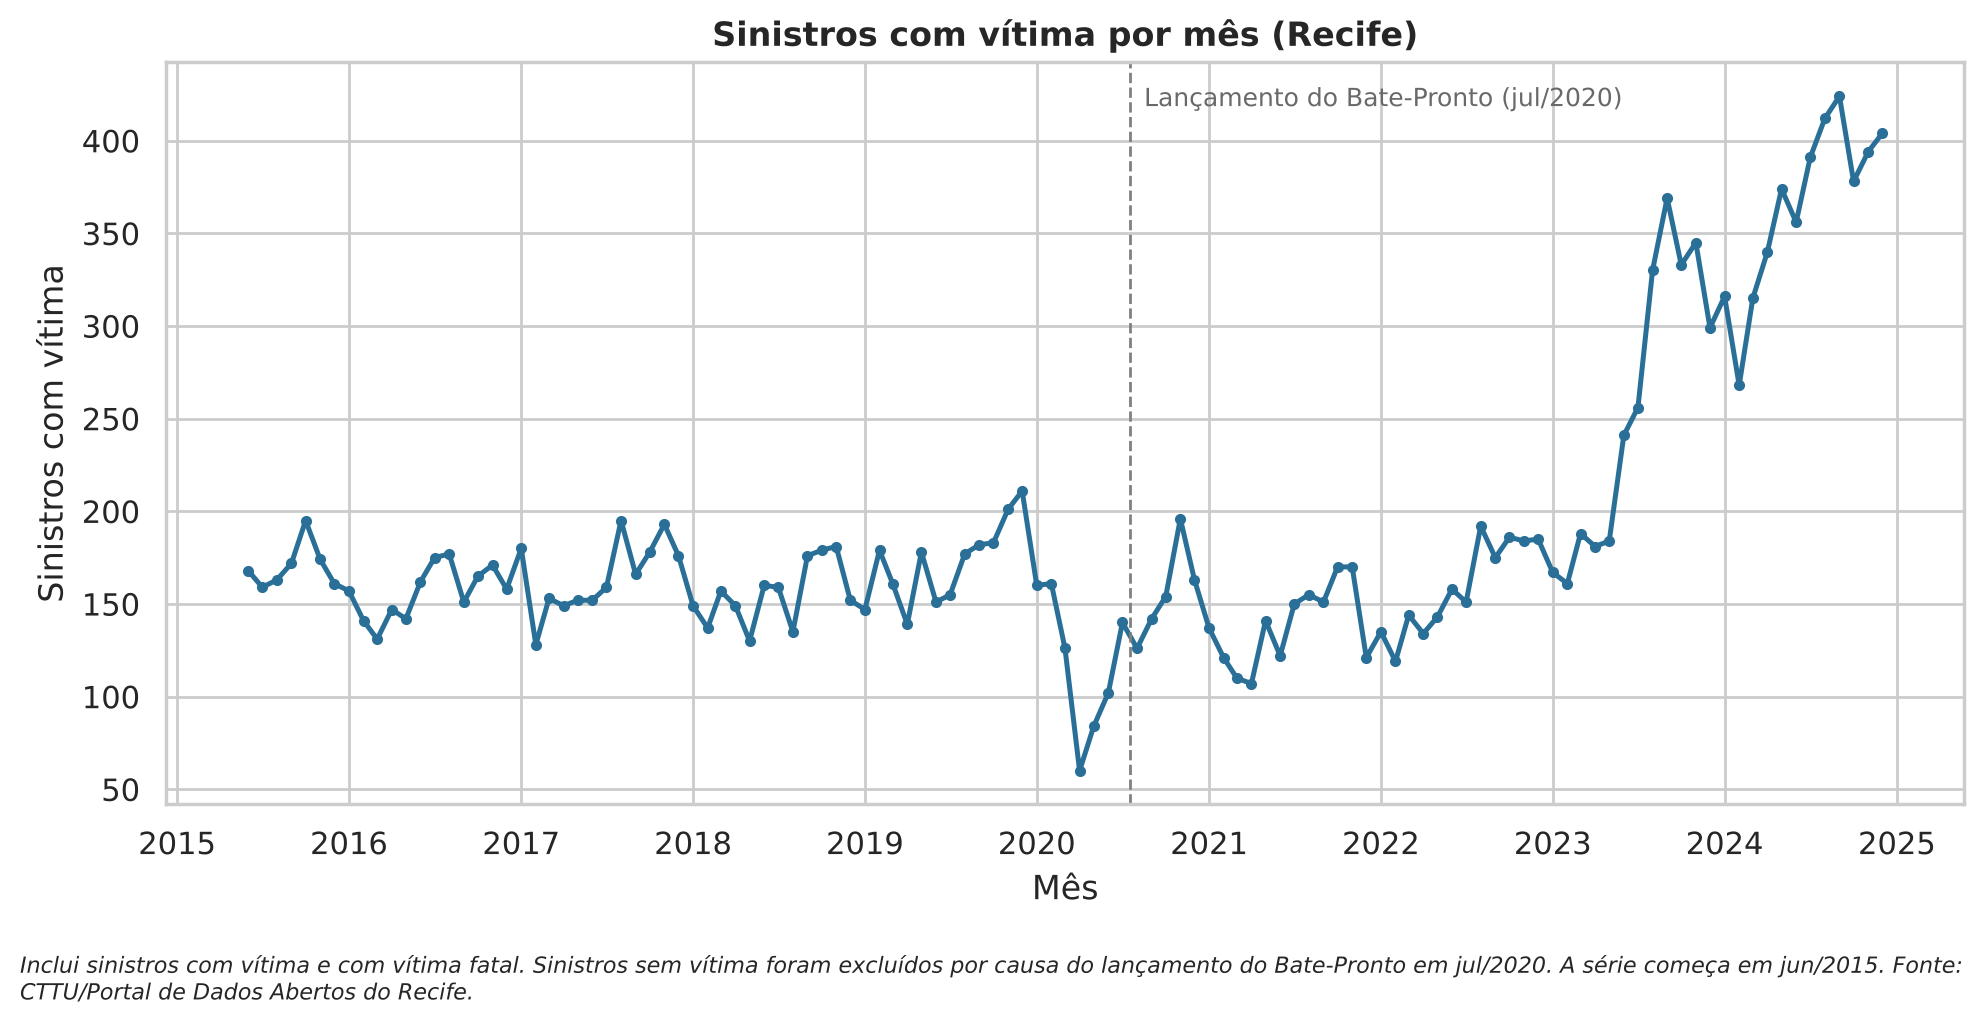

Salvo: docs/figuras/fig01_serie_temporal.png (300 dpi)


In [3]:
# fig01
s = carregar("serie_temporal", "gold_serie_temporal.csv")
cv = s[s["classificacao"].isin(["COM VITIMA", "VITIMA FATAL"])]
m = cv.groupby(["ano", "mes"], as_index=False)["sinistros"].sum()
m["periodo"] = pd.to_datetime(dict(year=m["ano"], month=m["mes"], day=1))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(m["periodo"], m["sinistros"], color=AZUL, lw=1.8, marker="o", ms=3)
ax.axvline(pd.Timestamp(DATA_BATE_PRONTO), color="gray", ls="--", lw=1)
ax.text(pd.Timestamp(DATA_BATE_PRONTO) + pd.Timedelta(days=30), ax.get_ylim()[1] * 0.97,
        "Lançamento do Bate-Pronto (jul/2020)", fontsize=9, color="dimgray", va="top")
ax.set_title("Sinistros com vítima por mês (Recife)")
ax.set_xlabel("Mês"); ax.set_ylabel("Sinistros com vítima")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
salvar_fig(fig, "fig01_serie_temporal.png",
           "Inclui sinistros com vítima e com vítima fatal. Sinistros sem vítima foram excluídos por causa do "
           "lançamento do Bate-Pronto em jul/2020. A série começa em jun/2015. Fonte: CTTU/Portal de Dados Abertos do Recife.")

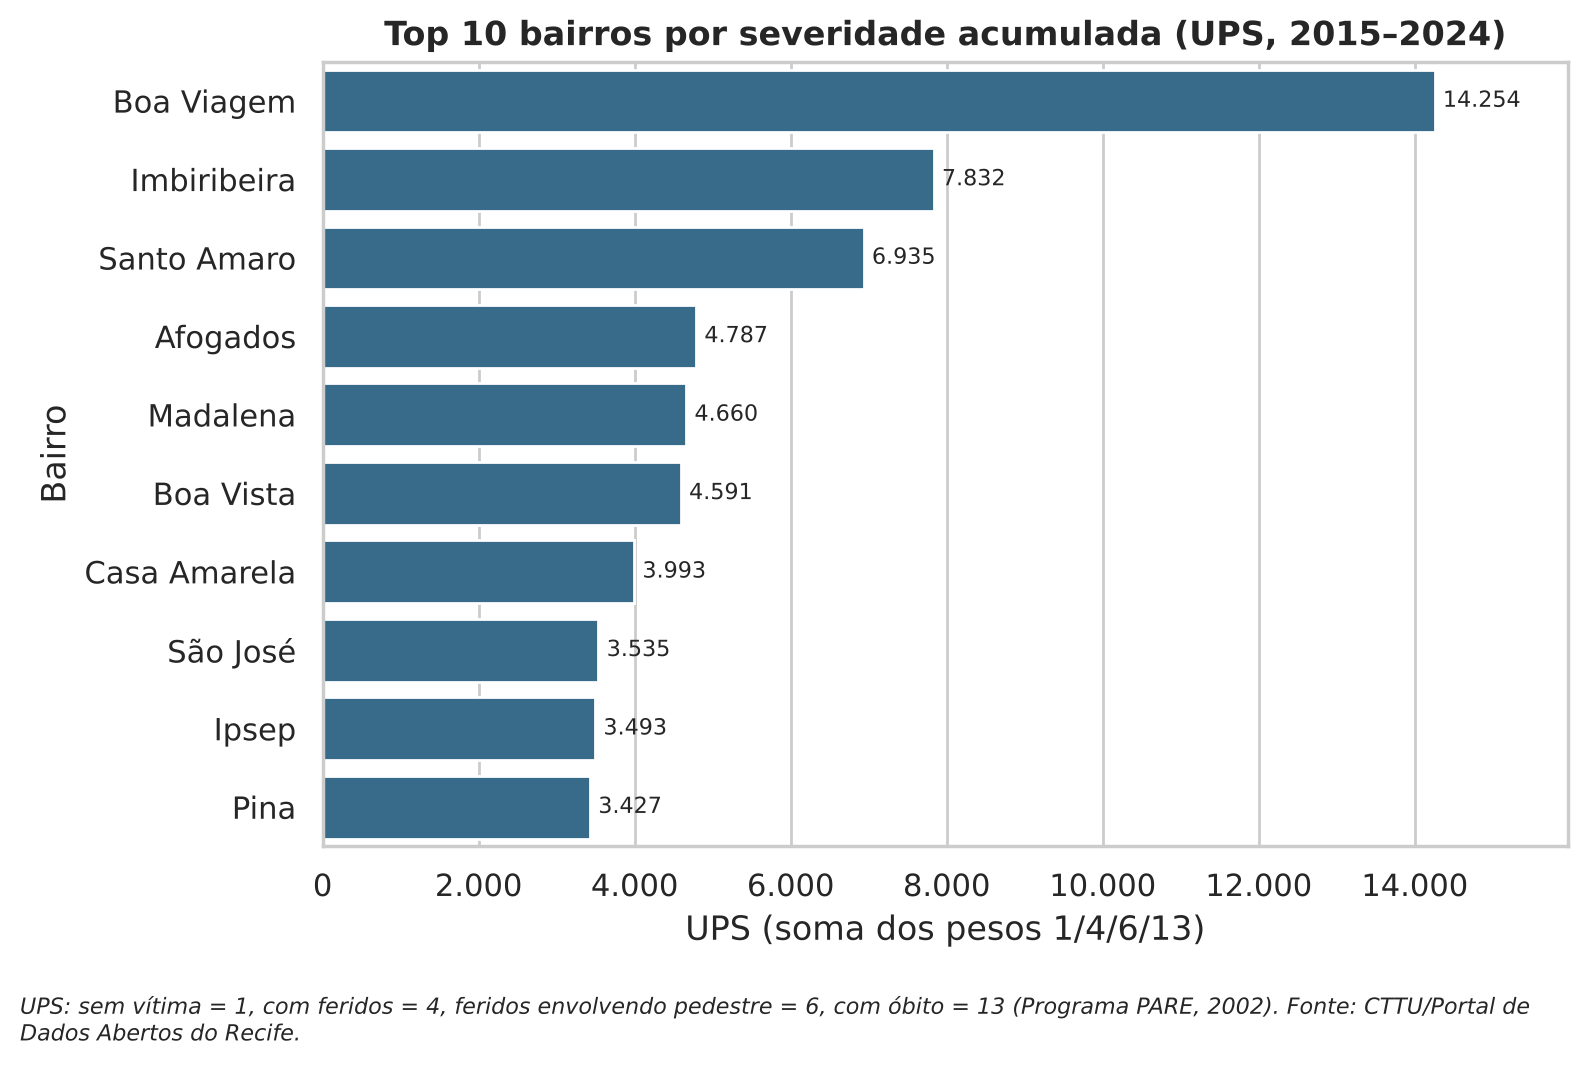

Salvo: docs/figuras/fig02_top10_bairros.png (300 dpi)


In [4]:
# fig02
b = carregar("top10_bairros", "gold_top10_bairros.csv").sort_values("ups", ascending=False)
b["bairro"] = b["bairro"].str.title().replace(ACENTOS_BAIRRO)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=b, y="bairro", x="ups", color=AZUL, ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[br(v) for v in c.datavalues], padding=3, fontsize=8)
ax.set_title("Top 10 bairros por severidade acumulada (UPS, 2015–2024)")
ax.set_xlabel("UPS (soma dos pesos 1/4/6/13)"); ax.set_ylabel("Bairro")
ax.set_xlim(0, b["ups"].max() * 1.12)
ax.xaxis.set_major_formatter(FMT_BR)
fig.tight_layout()
salvar_fig(fig, "fig02_top10_bairros.png",
           "UPS: sem vítima = 1, com feridos = 4, feridos envolvendo pedestre = 6, com óbito = 13 "
           "(Programa PARE, 2002). Fonte: CTTU/Portal de Dados Abertos do Recife.")

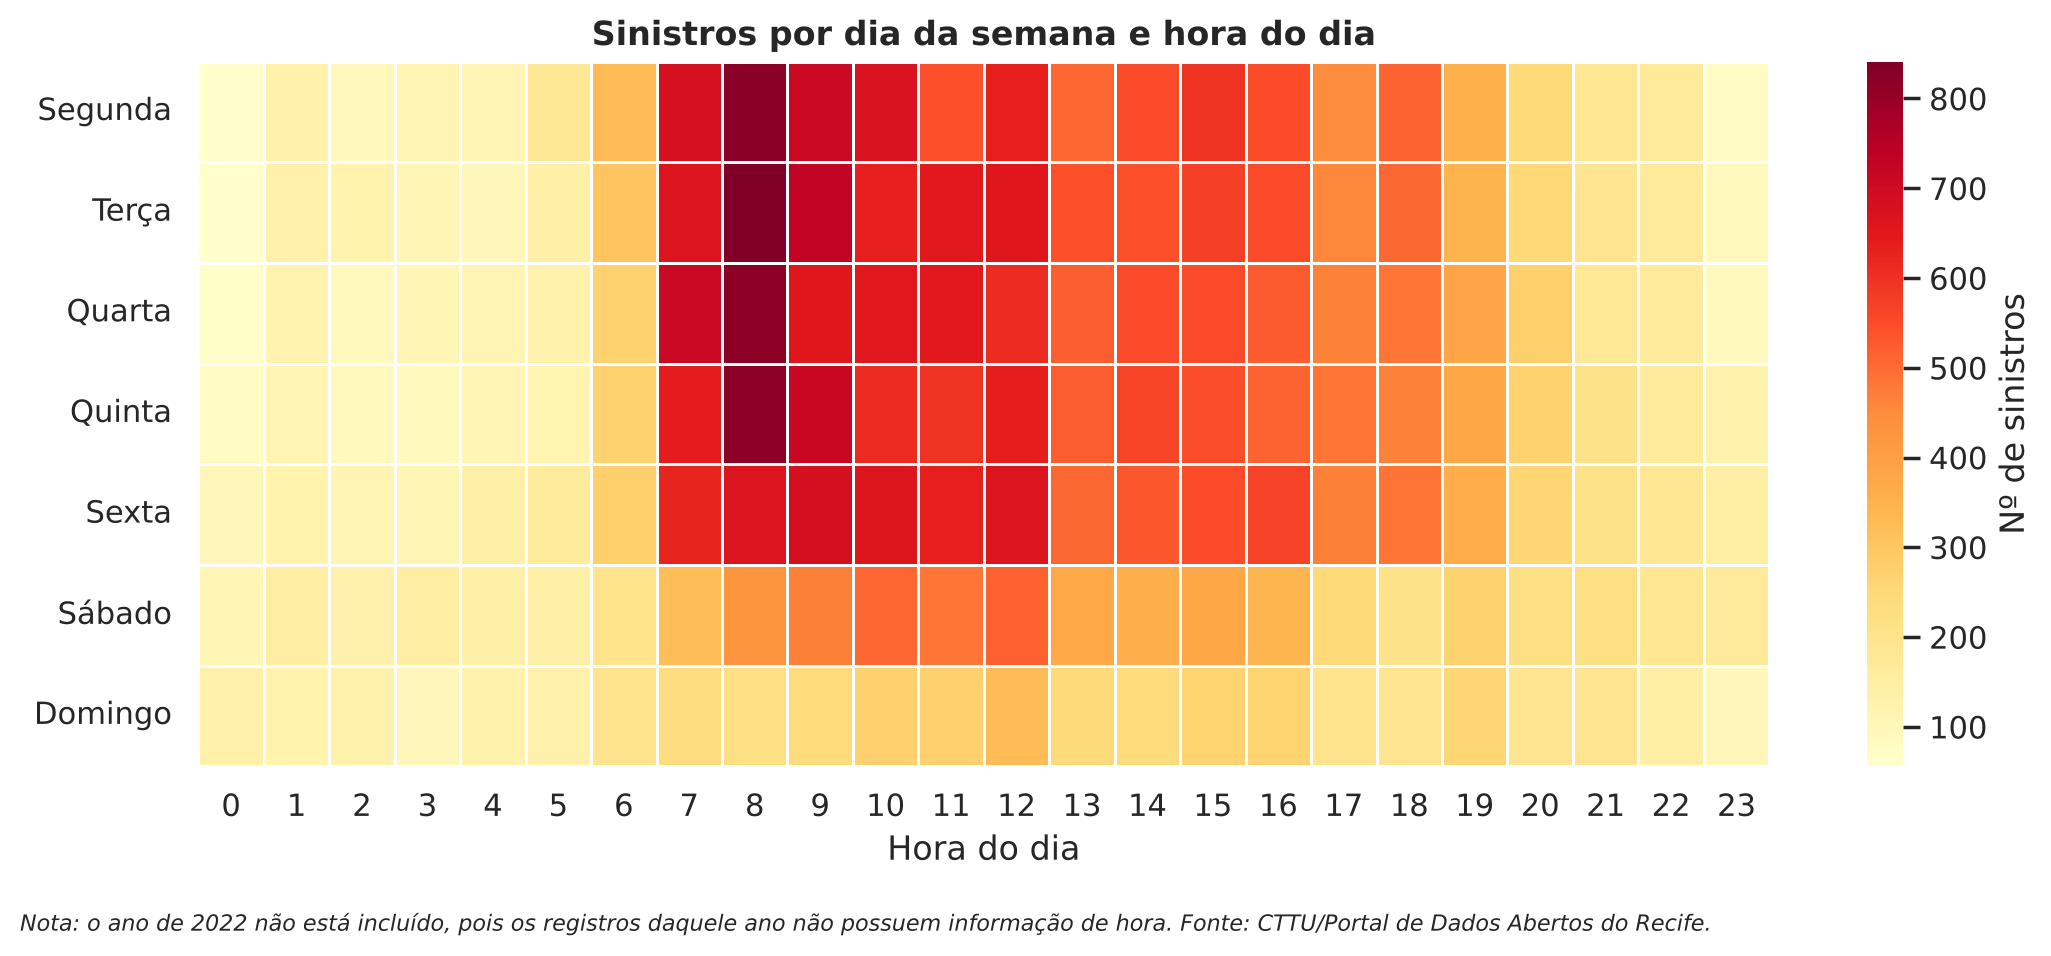

Salvo: docs/figuras/fig03_heatmap_dia_hora.png (300 dpi)


In [5]:
# fig03
h = carregar("dia_hora", "gold_heatmap_dia_hora.csv").set_index("dia_semana")
h.columns = h.columns.astype(float).astype(int)
ordem = ["SEGUNDA", "TERCA", "QUARTA", "QUINTA", "SEXTA", "SABADO", "DOMINGO"]
nomes = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
h = h.reindex(ordem); h.index = nomes

fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(h, cmap="YlOrRd", linewidths=.4, linecolor="white",
            cbar_kws={"label": "Nº de sinistros"}, ax=ax)
ax.set_title("Sinistros por dia da semana e hora do dia")
ax.set_xlabel("Hora do dia"); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
salvar_fig(fig, "fig03_heatmap_dia_hora.png",
           "Nota: o ano de 2022 não está incluído, pois os registros daquele ano não possuem informação de hora. "
           "Fonte: CTTU/Portal de Dados Abertos do Recife.")

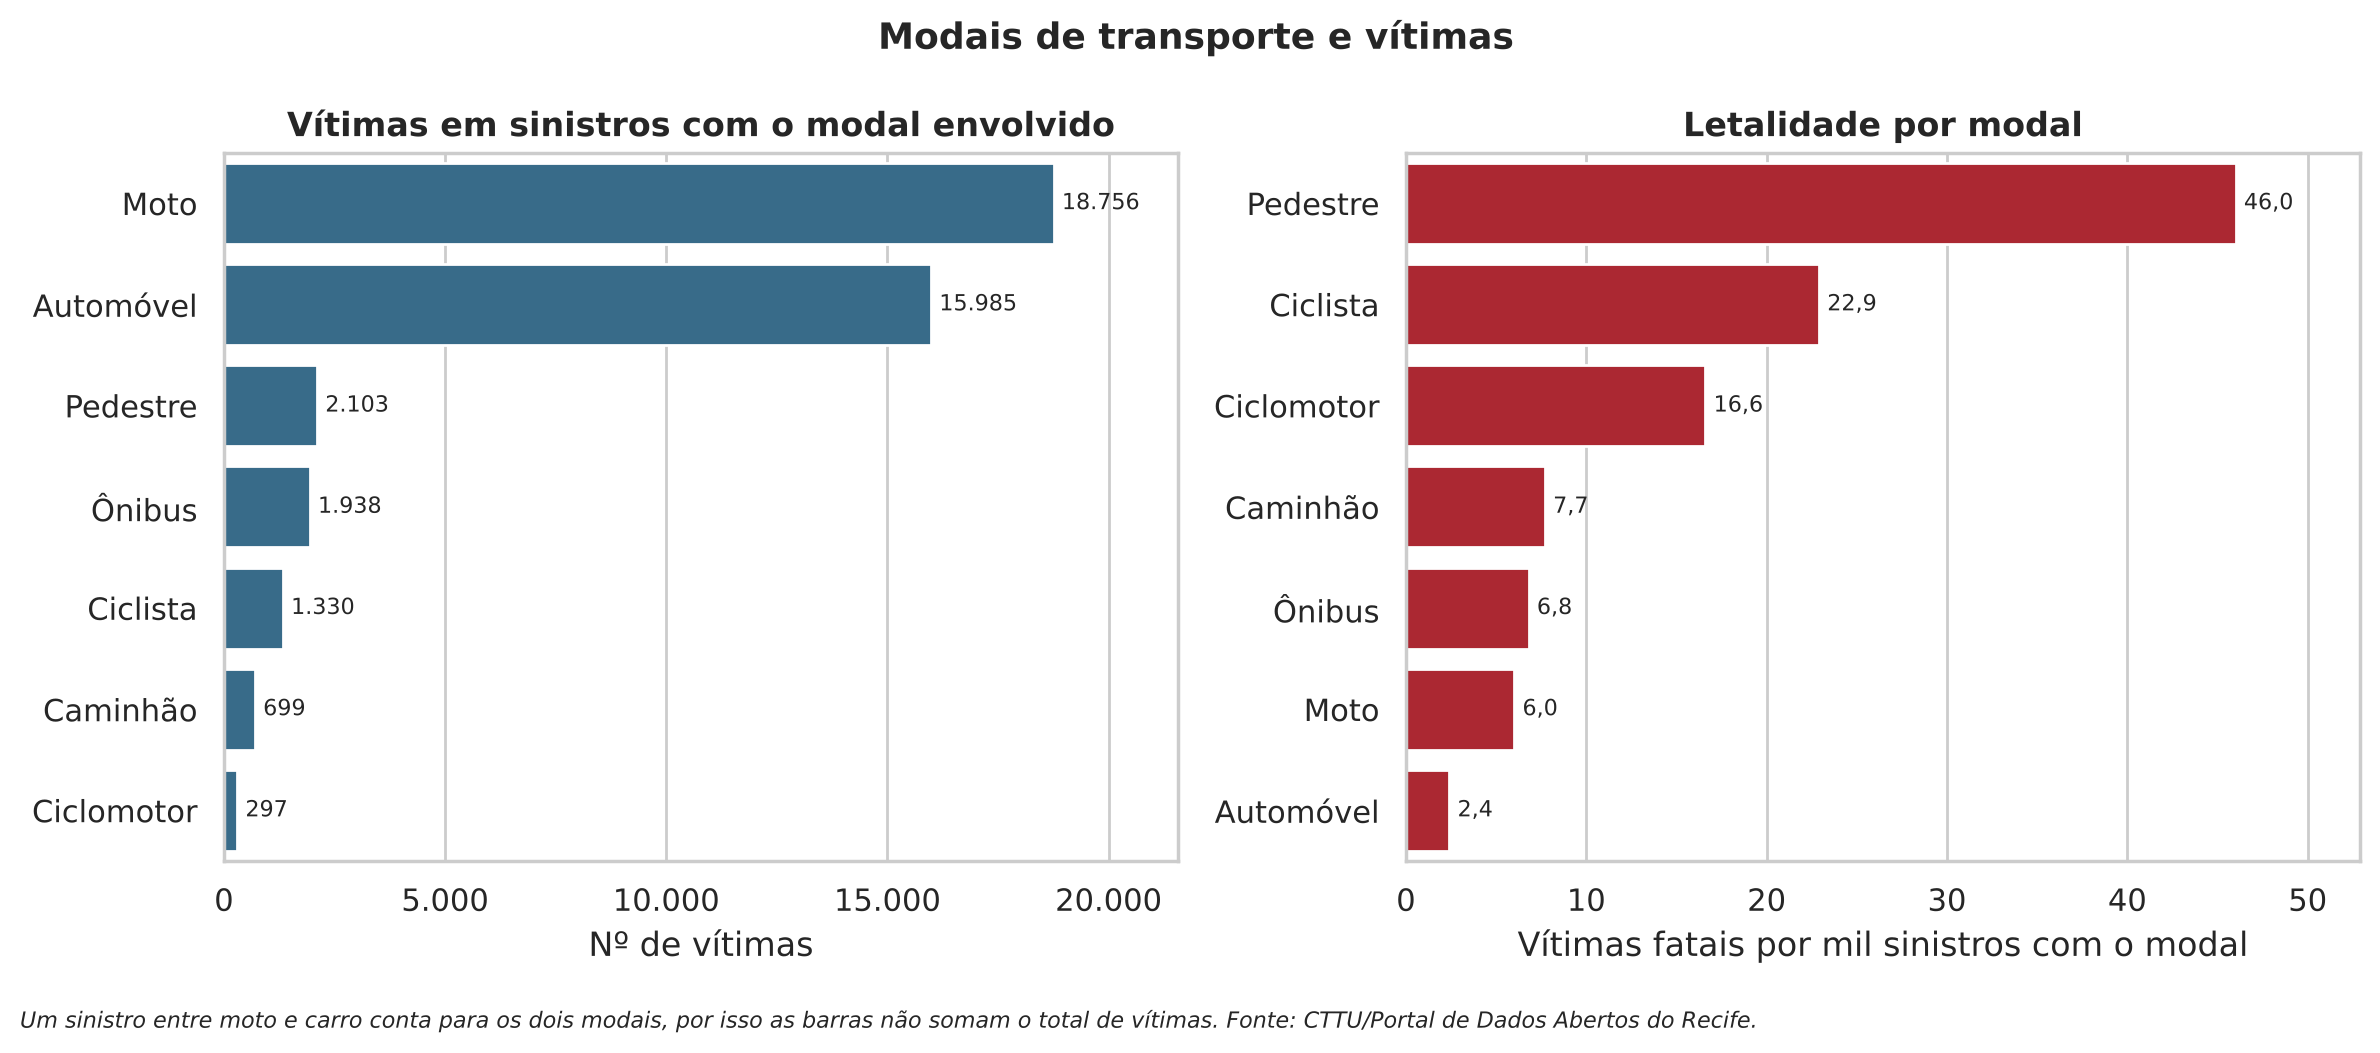

Salvo: docs/figuras/fig04_modais_vitimas.png (300 dpi)


In [6]:
# fig04
mo = carregar("modais", "gold_modais_vitimas.csv")
rot = {"MOTO": "Moto", "AUTO": "Automóvel", "PEDESTRE": "Pedestre", "ONIBUS": "Ônibus",
       "CICLISTA": "Ciclista", "CAMINHAO": "Caminhão", "CICLOM": "Ciclomotor"}
mo["modal"] = mo["modal"].map(rot).fillna(mo["modal"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
d1 = mo.sort_values("vitimas", ascending=False)
sns.barplot(data=d1, y="modal", x="vitimas", color=AZUL, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], labels=[br(v) for v in axes[0].containers[0].datavalues], padding=3, fontsize=8)
axes[0].set_title("Vítimas em sinistros com o modal envolvido"); axes[0].set_xlabel("Nº de vítimas"); axes[0].set_ylabel("")
axes[0].set_xlim(0, d1["vitimas"].max() * 1.15)
axes[0].xaxis.set_major_formatter(FMT_BR)
axes[0].xaxis.set_major_locator(plt.MaxNLocator(5))

d2 = mo.sort_values("fatais_por_mil", ascending=False)
sns.barplot(data=d2, y="modal", x="fatais_por_mil", color=VERMELHO, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], labels=[br(v, 1) for v in axes[1].containers[0].datavalues], padding=3, fontsize=8)
axes[1].set_title("Letalidade por modal"); axes[1].set_xlabel("Vítimas fatais por mil sinistros com o modal"); axes[1].set_ylabel("")
axes[1].set_xlim(0, d2["fatais_por_mil"].max() * 1.15)
fig.suptitle("Modais de transporte e vítimas", fontsize=13, fontweight="bold")
fig.tight_layout()
salvar_fig(fig, "fig04_modais_vitimas.png",
           "Um sinistro entre moto e carro conta para os dois modais, por isso as barras não somam o total de vítimas. "
           "Fonte: CTTU/Portal de Dados Abertos do Recife.")

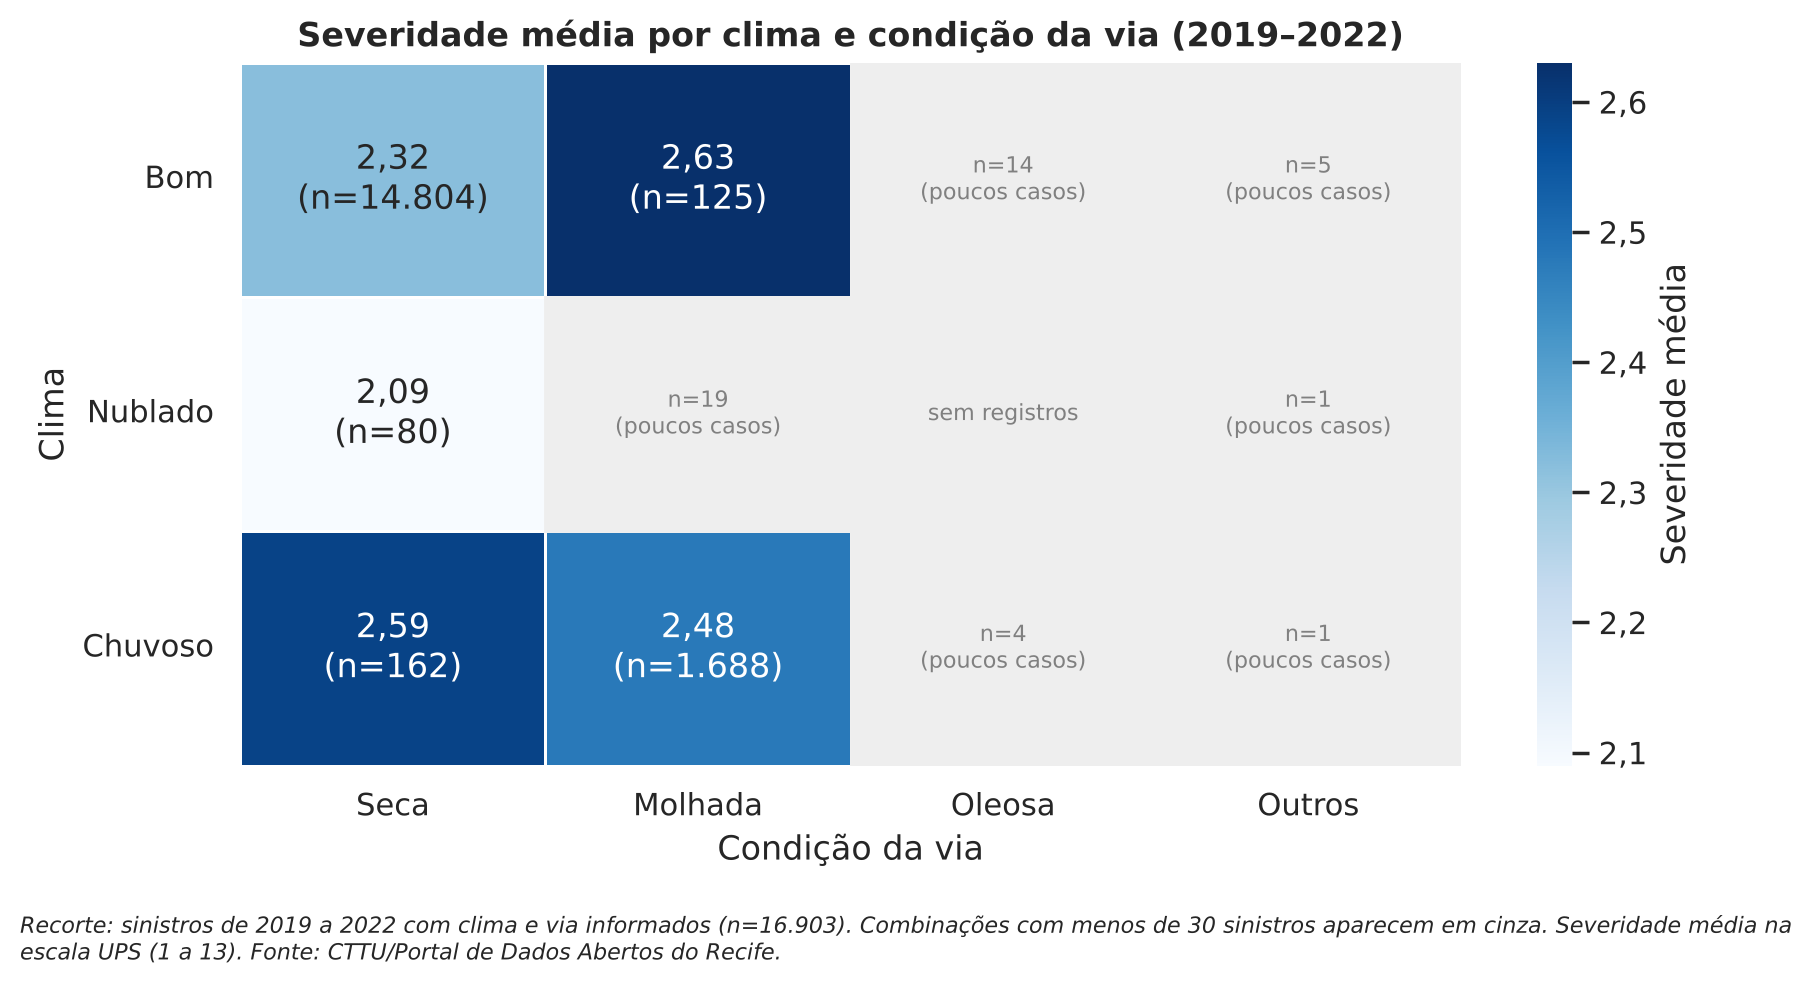

Salvo: docs/figuras/fig05_clima_via_severidade.png (300 dpi)


In [7]:
# fig05
c = carregar("clima_via", "gold_clima_via_severidade.csv")
MIN_N = 30                                    # abaixo disso a média é pouco confiável
sev = c.pivot(index="tempo_clima", columns="condicao_via", values="severidade_media")
n   = c.pivot(index="tempo_clima", columns="condicao_via", values="sinistros")
sev = sev.reindex(index=["BOM", "NUBLADO", "CHUVOSO"], columns=["SECA", "MOLHADA", "OLEOSA", "OUTROS"])
n   = n.reindex_like(sev)
anot = sev.copy().astype(object)
for i in sev.index:
    for j in sev.columns:
        anot.loc[i, j] = "" if pd.isna(sev.loc[i, j]) else f"{br(sev.loc[i, j], 2)}\n(n={br(n.loc[i, j])})"
mascara = sev.isna() | (n < MIN_N)

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.heatmap(sev, mask=mascara, annot=anot.where(~mascara, ""), fmt="", cmap="Blues",
            linewidths=.5, linecolor="white", cbar_kws={"label": "Severidade média"}, ax=ax)
# células com poucos casos: mostradas em cinza, com n
for i, ii in enumerate(sev.index):
    for j, jj in enumerate(sev.columns):
        if mascara.loc[ii, jj]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, color="#eeeeee", zorder=1))
            if not pd.isna(n.loc[ii, jj]):
                ax.text(j + .5, i + .5, f"n={int(n.loc[ii, jj])}\n(poucos casos)", ha="center",
                        va="center", fontsize=8, color="gray")
            else:
                ax.text(j + .5, i + .5, "sem registros", ha="center", va="center", fontsize=8, color="gray")
ax.set_xticklabels([t.get_text().title() for t in ax.get_xticklabels()], rotation=0)
ax.set_yticklabels([t.get_text().title() for t in ax.get_yticklabels()], rotation=0)
ax.set_title("Severidade média por clima e condição da via (2019–2022)")
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 1)))
ax.set_xlabel("Condição da via"); ax.set_ylabel("Clima")
fig.tight_layout()
salvar_fig(fig, "fig05_clima_via_severidade.png",
           f"Recorte: sinistros de 2019 a 2022 com clima e via informados (n={br(c['sinistros'].sum())}). "
           f"Combinações com menos de {MIN_N} sinistros aparecem em cinza. Severidade média na escala UPS (1 a 13). "
           "Fonte: CTTU/Portal de Dados Abertos do Recife.")